In [23]:
import pandas as pd
import numpy as np

In [24]:
df = pd.read_csv("careflow_raw_events_5000_visits.csv")
df

,case_id,activity,timestamp,department,shift,patient_category,resource
0,P00001,Registration,2026-10-07 20:32:41,Emergency,Afternoon,Adult,Registration_02
1,P00001,Triage,2026-10-07 20:42:41,Emergency,Afternoon,Adult,Nurse_03
2,P00001,Lab Test,2026-10-07 20:49:41,Emergency,Afternoon,Adult,LabTech_02
3,P00001,Treatment,2026-10-07 21:12:41,Emergency,Afternoon,Adult,Nurse_02
4,P00001,Doctor Consultation,2026-10-07 21:25:41,Emergency,Afternoon,Adult,Doctor_02
...,...,...,...,...,...,...,...
27957,P04999,Discharge,2026-11-04 03:43:30,Emergency,Night,Adult,Discharge_02
27958,P05000,Registration,2026-10-28 14:40:44,Emergency,Afternoon,Adult,Registration_02
27959,P05000,Triage,2026-10-28 14:46:44,Emergency,Afternoon,Adult,Nurse_03
27960,P05000,Doctor Consultation,2026-10-28 14:56:44,Emergency,Afternoon,Adult,Doctor_02


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Work on a copy of your BigQuery DataFrame
df = df.copy()

# Standardize timestamps and sort events
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
df = df.dropna(subset=["case_id", "activity", "timestamp"]).copy()
df["case_id"] = df["case_id"].astype(str)
df["activity"] = df["activity"].astype(str)

df = df.sort_values(["case_id", "timestamp"]).reset_index(drop=True)

# Create previous/next event information
df["previous_activity"] = df.groupby("case_id")["activity"].shift(1)
df["next_activity"] = df.groupby("case_id")["activity"].shift(-1)
df["previous_timestamp"] = df.groupby("case_id")["timestamp"].shift(1)
df["next_timestamp"] = df.groupby("case_id")["timestamp"].shift(-1)

# Elapsed time until the next recorded activity
df["elapsed_minutes"] = (
    df["next_timestamp"] - df["timestamp"]
).dt.total_seconds() / 60

# Transition, e.g. X-Ray → Return to Triage
df["transition"] = (
    df["activity"] + " → " + df["next_activity"].fillna("End of visit")
)

print("Total events:", len(df))
print("Total visits:", df["case_id"].nunique())
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
display(df.head())


Total events: 27962
Total visits: 5000
Date range: 2026-10-05 00:00:02+00:00 to 2026-11-06 01:16:35+00:00


,case_id,activity,timestamp,department,shift,patient_category,resource,previous_activity,next_activity,previous_timestamp,next_timestamp,elapsed_minutes,transition
0,P00001,Registration,2026-10-07 20:32:41+00:00,Emergency,Afternoon,Adult,Registration_02,NaN,Triage,NaT,2026-10-07 20:42:41+00:00,10.0,Registration → Triage
1,P00001,Triage,2026-10-07 20:42:41+00:00,Emergency,Afternoon,Adult,Nurse_03,Registration,Lab Test,2026-10-07 20:32:41+00:00,2026-10-07 20:49:41+00:00,7.0,Triage → Lab Test
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Emergency,Afternoon,Adult,LabTech_02,Triage,Treatment,2026-10-07 20:42:41+00:00,2026-10-07 21:12:41+00:00,23.0,Lab Test → Treatment
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Emergency,Afternoon,Adult,Nurse_02,Lab Test,Doctor Consultation,2026-10-07 20:49:41+00:00,2026-10-07 21:25:41+00:00,13.0,Treatment → Doctor Consultation
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Emergency,Afternoon,Adult,Doctor_02,Treatment,Discharge,2026-10-07 21:12:41+00:00,2026-10-07 21:32:41+00:00,7.0,Doctor Consultation → Discharge


In [26]:
#Data quality checks

# Missing values in each column
missing_summary = df.isna().sum().rename("missing_count").to_frame()
missing_summary["missing_pct"] = (
    missing_summary["missing_count"] / len(df) * 100
)
display(missing_summary)

# Duplicate event records
duplicate_count = df.duplicated(
    subset=["case_id", "activity", "timestamp"]
).sum()
print("Duplicate case/activity/timestamp records:", duplicate_count)

# Negative time intervals between consecutive events
negative_intervals = df[df["elapsed_minutes"] < 0]
print("Negative transition intervals:", len(negative_intervals))

# Events per visit
events_per_visit = df.groupby("case_id").size().rename("event_count")
display(events_per_visit.describe().to_frame())

# Visits with more than 8 events: inspect rather than automatically delete
print("Visits with more than 8 events:", (events_per_visit > 8).sum())


,missing_count,missing_pct
case_id,0,0.00000
activity,0,0.00000
timestamp,0,0.00000
department,0,0.00000
shift,0,0.00000
patient_category,0,0.00000
resource,0,0.00000
previous_activity,5000,17.88141
next_activity,5000,17.88141
previous_timestamp,5000,17.88141


Duplicate case/activity/timestamp records: 0
Negative transition intervals: 0


,event_count
count,5000.000000
mean,5.592400
std,1.248749
min,4.000000
25%,5.000000
50%,5.000000
75%,6.000000
max,8.000000


Visits with more than 8 events: 0


In [27]:
#Main project KPIs

total_visits = df["case_id"].nunique()
total_events = len(df)

return_ids = set(
    df.loc[df["activity"].eq("Return to Triage"), "case_id"].unique()
)

returned_visits = len(return_ids)
return_rate = returned_visits / total_visits * 100 if total_visits else 0

activity_counts = df["activity"].value_counts()
activity_summary = activity_counts.rename_axis("activity").reset_index(
    name="event_count"
)
activity_summary["pct_of_all_events"] = (
    activity_summary["event_count"] / total_events * 100
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total visits",
        "Total recorded events",
        "Visits with Return to Triage",
        "Return-to-triage rate (%)",
        "Average events per visit",
        "Median events per visit"
    ],
    "Value": [
        total_visits,
        total_events,
        returned_visits,
        round(return_rate, 2),
        round(events_per_visit.mean(), 2),
        round(events_per_visit.median(), 2)
    ]
})

display(kpi_summary)
display(activity_summary)


,KPI,Value
0,Total visits,5000.00
1,Total recorded events,27962.00
2,Visits with Return to Triage,1141.00
3,Return-to-triage rate (%),22.82
4,Average events per visit,5.59
5,Median events per visit,5.00


,activity,event_count,pct_of_all_events
0,Triage,6141,21.961948
1,Registration,5000,17.881410
2,Doctor Consultation,5000,17.881410
3,Discharge,4601,16.454474
4,X-Ray,2815,10.067234
5,Lab Test,1476,5.278592
6,Treatment,1389,4.967456
7,Return to Triage,1141,4.080538
8,Admission,399,1.426937


In [28]:
#Return-to-triage analysis
# A. Return-to-triage events and visit-level rate
return_events = df[df["activity"].eq("Return to Triage")].copy()

print("Return-to-triage events:", len(return_events))
print("Distinct visits with a return:", return_events["case_id"].nunique())
print(
    "Visit-level return rate:",
    round(return_events["case_id"].nunique() / total_visits * 100, 2),
    "%"
)

# B. Activity immediately before each return
print("\nActivity immediately before Return to Triage:")
display(
    return_events["previous_activity"]
    .fillna("No previous activity")
    .value_counts()
    .rename_axis("previous_activity")
    .reset_index(name="return_events")
)

# C. Activity immediately after each return
print("\nActivity immediately after Return to Triage:")
display(
    return_events["next_activity"]
    .fillna("End of visit")
    .value_counts()
    .rename_axis("next_activity")
    .reset_index(name="return_events")
)

# D. Check the specific X-Ray → Return to Triage transition
xray_returns = df[
    df["activity"].eq("X-Ray")
    & df["next_activity"].eq("Return to Triage")
]

print("\nX-Ray → Return to Triage transitions:", len(xray_returns))

# E. Visit-level return flag
visit_return_flag = (
    df.groupby("case_id")["activity"]
    .apply(lambda activities: activities.eq("Return to Triage").any())
    .rename("returned_to_triage")
)

print("\nVisit-level return flag:")
display(visit_return_flag.value_counts().rename_axis("returned_to_triage").to_frame("visits"))


Return-to-triage events: 1141
Distinct visits with a return: 1141
Visit-level return rate: 22.82 %

Activity immediately before Return to Triage:


,previous_activity,return_events
0,X-Ray,1141



Activity immediately after Return to Triage:


,next_activity,return_events
0,Triage,1141



X-Ray → Return to Triage transitions: 1141

Visit-level return flag:


,visits
returned_to_triage,
False,3859
True,1141


In [29]:
#Visit duration analysis

visit_summary = (
    df.groupby("case_id")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        event_count=("activity", "size"),
        shift=("shift", "first"),
        patient_category=("patient_category", "first")
    )
    .reset_index()
)

visit_summary["duration_minutes"] = (
    visit_summary["end_time"] - visit_summary["start_time"]
).dt.total_seconds() / 60

visit_summary["returned_to_triage"] = (
    visit_summary["case_id"].isin(return_ids)
)

# Overall duration distribution
display(visit_summary["duration_minutes"].describe().to_frame("duration_minutes"))

# Compare visits with and without a return
duration_comparison = (
    visit_summary.groupby("returned_to_triage")["duration_minutes"]
    .agg(
        visit_count="count",
        mean_minutes="mean",
        median_minutes="median",
        min_minutes="min",
        max_minutes="max"
    )
    .round(2)
)

display(duration_comparison)

# Difference between the two groups
duration_means = visit_summary.groupby("returned_to_triage")["duration_minutes"].mean()
if True in duration_means.index and False in duration_means.index:
    mean_difference = duration_means.loc[True] - duration_means.loc[False]
    print("Mean duration difference (return minus no return):",
          round(mean_difference, 2), "minutes")


,duration_minutes
count,5000.000000
mean,80.233000
std,28.333155
min,16.000000
25%,60.000000
50%,78.000000
75%,98.000000
max,201.000000


,visit_count,mean_minutes,median_minutes,min_minutes,max_minutes
returned_to_triage,,,,,
False,3859,72.09,70.0,16.0,174.0
True,1141,107.78,106.0,49.0,201.0


Mean duration difference (return minus no return): 35.69 minutes


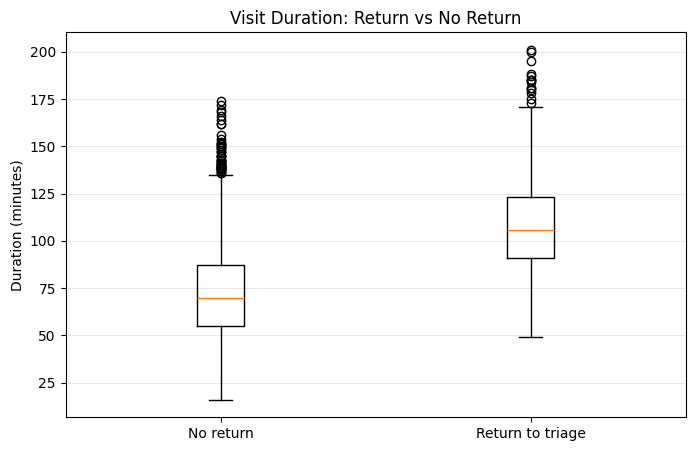

In [30]:
#Plot: visit duration with and without return

duration_groups = [
    visit_summary.loc[
        ~visit_summary["returned_to_triage"], "duration_minutes"
    ],
    visit_summary.loc[
        visit_summary["returned_to_triage"], "duration_minutes"
    ]
]

plt.figure(figsize=(8, 5))
plt.boxplot(duration_groups, tick_labels=["No return", "Return to triage"])
plt.title("Visit Duration: Return vs No Return")
plt.ylabel("Duration (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [31]:
#Shift-wise analysis

shift_summary = (
    visit_summary.groupby("shift", dropna=False)
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration_minutes=("duration_minutes", "mean"),
        median_duration_minutes=("duration_minutes", "median")
    )
    .reset_index()
)

shift_summary["return_rate_pct"] = (
    shift_summary["return_visits"] / shift_summary["total_visits"] * 100
).round(2)

shift_summary = shift_summary.round({
    "mean_duration_minutes": 2,
    "median_duration_minutes": 2
})

display(shift_summary.sort_values("return_rate_pct", ascending=False))



,shift,total_visits,return_visits,mean_duration_minutes,median_duration_minutes,return_rate_pct
0,Afternoon,1627,393,80.80,78.0,24.15
1,Morning,1677,383,80.27,78.0,22.84
2,Night,1696,365,79.65,77.0,21.52


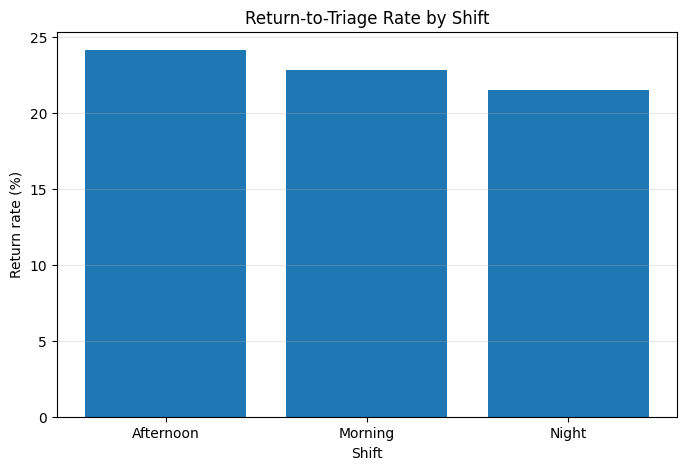

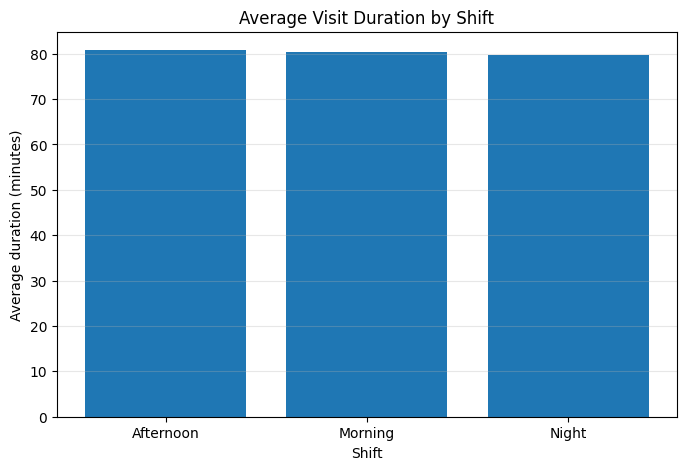

In [32]:

# Shift-wise return rate
plot_data = shift_summary.sort_values("shift")

plt.figure(figsize=(8, 5))
plt.bar(plot_data["shift"].astype(str), plot_data["return_rate_pct"])
plt.title("Return-to-Triage Rate by Shift")
plt.xlabel("Shift")
plt.ylabel("Return rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Shift-wise average visit duration
plt.figure(figsize=(8, 5))
plt.bar(
    plot_data["shift"].astype(str),
    plot_data["mean_duration_minutes"]
)
plt.title("Average Visit Duration by Shift")
plt.xlabel("Shift")
plt.ylabel("Average duration (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [33]:
# Patient-category analysis

category_summary = (
    visit_summary.groupby("patient_category", dropna=False)
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration_minutes=("duration_minutes", "mean"),
        median_duration_minutes=("duration_minutes", "median")
    )
    .reset_index()
)

category_summary["return_rate_pct"] = (
    category_summary["return_visits"] / category_summary["total_visits"] * 100
).round(2)

category_summary = category_summary.round({
    "mean_duration_minutes": 2,
    "median_duration_minutes": 2
})

display(category_summary.sort_values("return_rate_pct", ascending=False))


,patient_category,total_visits,return_visits,mean_duration_minutes,median_duration_minutes,return_rate_pct
1,Child,606,147,79.84,77.0,24.26
0,Adult,3513,805,80.44,78.0,22.91
2,Older Adult,881,189,79.68,76.0,21.45


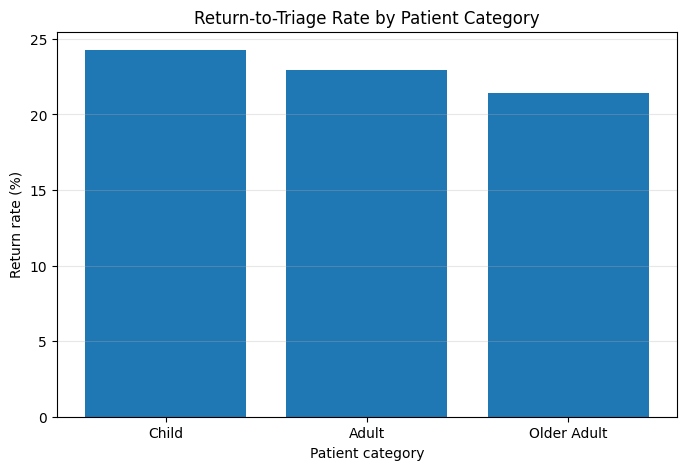

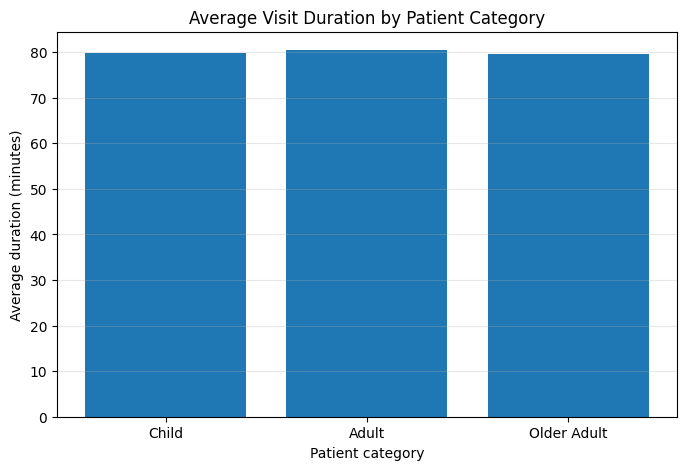

In [34]:

# Return rate by patient category
category_plot = category_summary.sort_values("return_rate_pct", ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(
    category_plot["patient_category"].astype(str),
    category_plot["return_rate_pct"]
)
plt.title("Return-to-Triage Rate by Patient Category")
plt.xlabel("Patient category")
plt.ylabel("Return rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Average duration by patient category
plt.figure(figsize=(8, 5))
plt.bar(
    category_plot["patient_category"].astype(str),
    category_plot["mean_duration_minutes"]
)
plt.title("Average Visit Duration by Patient Category")
plt.xlabel("Patient category")
plt.ylabel("Average duration (minutes)")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [35]:
#Activity transition analysis: identify potential bottlenecks

valid_transitions = df.dropna(
    subset=["next_activity", "elapsed_minutes"]
).copy()

# Exclude negative intervals from time summaries
valid_transitions = valid_transitions[
    valid_transitions["elapsed_minutes"] >= 0
]

transition_summary = (
    valid_transitions.groupby("transition")
    .agg(
        transition_count=("elapsed_minutes", "size"),
        mean_minutes=("elapsed_minutes", "mean"),
        median_minutes=("elapsed_minutes", "median"),
        p90_minutes=("elapsed_minutes", lambda s: s.quantile(0.90))
    )
    .reset_index()
    .round(2)
)

# Focus on transitions with enough observations
frequent_transitions = transition_summary[
    transition_summary["transition_count"] >= 30
].copy()

display(
    frequent_transitions
    .sort_values("median_minutes", ascending=False)
    .head(15)
)


,transition,transition_count,mean_minutes,median_minutes,p90_minutes
0,Doctor Consultation → Admission,399,51.84,51.0,84.0
6,Treatment → Doctor Consultation,1389,25.15,25.0,41.0
7,Triage → Doctor Consultation,1746,25.08,25.0,42.0
11,X-Ray → Doctor Consultation,887,24.93,25.0,41.0
2,Lab Test → Doctor Consultation,978,24.45,24.0,41.0
10,Triage → X-Ray,2815,19.86,20.0,32.0
12,X-Ray → Lab Test,241,17.83,19.0,29.0
9,Triage → Treatment,345,18.18,18.0,28.0
1,Doctor Consultation → Discharge,4601,17.59,18.0,28.0
3,Lab Test → Treatment,498,17.36,17.0,28.0


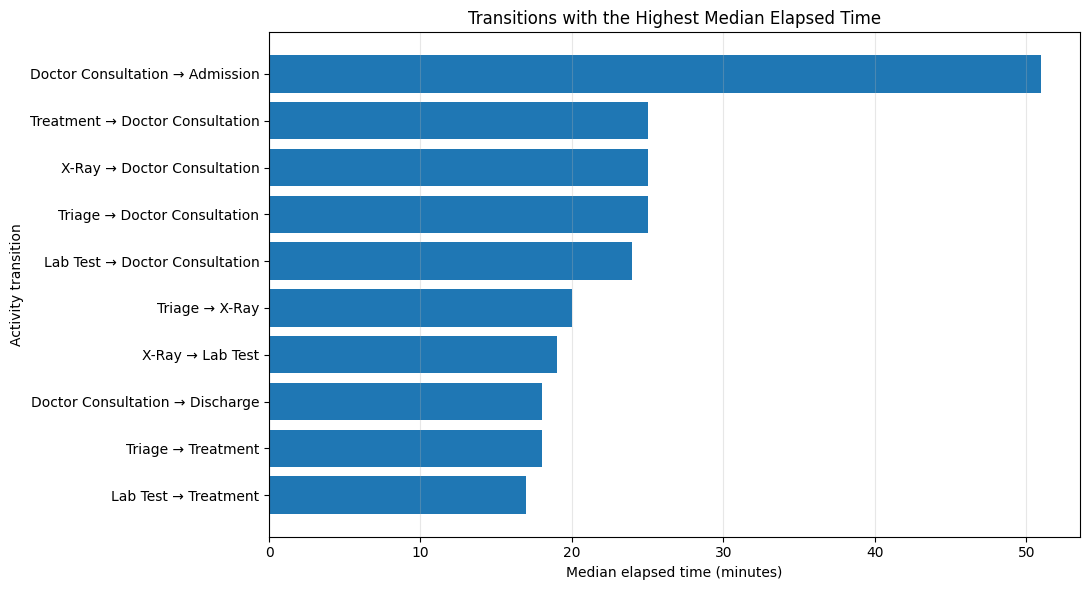

In [36]:

# Plot the 10 most frequent transitions by median elapsed time
top_transitions = (
    frequent_transitions
    .sort_values("median_minutes", ascending=False)
    .head(10)
    .sort_values("median_minutes")
)

plt.figure(figsize=(11, 6))
plt.barh(top_transitions["transition"], top_transitions["median_minutes"])
plt.title("Transitions with the Highest Median Elapsed Time")
plt.xlabel("Median elapsed time (minutes)")
plt.ylabel("Activity transition")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [37]:
#9. Common patient pathways and process variants
# Build one ordered activity sequence per visit
pathways = (
    df.groupby("case_id")["activity"]
    .agg(lambda activities: " → ".join(activities.tolist()))
    .rename("pathway")
    .reset_index()
)

pathway_counts = (
    pathways.groupby("pathway")
    .agg(visit_count=("case_id", "nunique"))
    .reset_index()
    .sort_values("visit_count", ascending=False)
)

pathway_counts["visit_pct"] = (
    pathway_counts["visit_count"] / total_visits * 100
).round(2)

print("Top 15 most common pathways:")
display(pathway_counts.head(15))

# Number of unique pathways
print("Number of unique pathway variants:", pathways["pathway"].nunique())


Top 15 most common pathways:


,pathway,visit_count,visit_pct
1,Registration → Triage → Doctor Consultation → ...,1035,20.70
7,Registration → Triage → X-Ray → Doctor Consult...,819,16.38
11,Registration → Triage → X-Ray → Return to Tria...,579,11.58
3,Registration → Triage → Lab Test → Doctor Cons...,517,10.34
17,Registration → Triage → X-Ray → Treatment → Do...,504,10.08
5,Registration → Triage → Lab Test → Treatment →...,453,9.06
15,Registration → Triage → X-Ray → Return to Tria...,317,6.34
9,Registration → Triage → X-Ray → Lab Test → Doc...,220,4.40
13,Registration → Triage → X-Ray → Return to Tria...,157,3.14
0,Registration → Triage → Doctor Consultation → ...,86,1.72


Number of unique pathway variants: 18


In [38]:
# Compare common pathways between return and no-return visits
pathway_detail = pathways.merge(
    visit_summary[["case_id", "returned_to_triage"]],
    on="case_id",
    how="left"
)

pathway_comparison = (
    pathway_detail.groupby(["returned_to_triage", "pathway"])
    .size()
    .reset_index(name="visit_count")
    .sort_values(["returned_to_triage", "visit_count"], ascending=[True, False])
)

print("Most common pathways WITHOUT a return:")
display(
    pathway_comparison[
        pathway_comparison["returned_to_triage"].eq(False)
    ].head(10)
)

print("Most common pathways WITH a return:")
display(
    pathway_comparison[
        pathway_comparison["returned_to_triage"].eq(True)
    ].head(10)
)


Most common pathways WITHOUT a return:


,returned_to_triage,pathway,visit_count
1,False,Registration → Triage → Doctor Consultation → ...,1035
7,False,Registration → Triage → X-Ray → Doctor Consult...,819
3,False,Registration → Triage → Lab Test → Doctor Cons...,517
11,False,Registration → Triage → X-Ray → Treatment → Do...,504
5,False,Registration → Triage → Lab Test → Treatment →...,453
9,False,Registration → Triage → X-Ray → Lab Test → Doc...,220
0,False,Registration → Triage → Doctor Consultation → ...,86
6,False,Registration → Triage → X-Ray → Doctor Consult...,68
2,False,Registration → Triage → Lab Test → Doctor Cons...,49
4,False,Registration → Triage → Lab Test → Treatment →...,45


Most common pathways WITH a return:


,returned_to_triage,pathway,visit_count
13,True,Registration → Triage → X-Ray → Return to Tria...,579
17,True,Registration → Triage → X-Ray → Return to Tria...,317
15,True,Registration → Triage → X-Ray → Return to Tria...,157
12,True,Registration → Triage → X-Ray → Return to Tria...,46
16,True,Registration → Triage → X-Ray → Return to Tria...,28
14,True,Registration → Triage → X-Ray → Return to Tria...,14


In [39]:
#10. Department and resource workload

# Activity volume by department
department_workload = (
    df.groupby("department", dropna=False)
    .agg(
        event_count=("activity", "size"),
        unique_visits=("case_id", "nunique"),
        unique_resources=("resource", "nunique")
    )
    .reset_index()
    .sort_values("event_count", ascending=False)
)

department_workload["event_pct"] = (
    department_workload["event_count"] / total_events * 100
).round(2)

display(department_workload)

# Activity volume by resource
resource_workload = (
    df.groupby("resource", dropna=False)
    .agg(
        event_count=("activity", "size"),
        unique_visits=("case_id", "nunique"),
        unique_activities=("activity", "nunique")
    )
    .reset_index()
    .sort_values("event_count", ascending=False)
)

display(resource_workload.head(20))


,department,event_count,unique_visits,unique_resources,event_pct
0,Emergency,27962,5000,16,100.0


,resource,event_count,unique_visits,unique_activities
9,Nurse_01,3109,2504,3
10,Nurse_02,3086,2469,3
14,Registration_01,2510,2510,1
15,Registration_02,2490,2490,1
11,Nurse_03,2476,2128,2
3,Discharge_02,2307,2307,1
2,Discharge_01,2294,2294,1
6,Doctor_03,1706,1706,1
4,Doctor_01,1653,1653,1
5,Doctor_02,1641,1641,1


In [40]:

# Events by activity and department
activity_department = pd.crosstab(
    df["activity"], df["department"], margins=True
)
display(activity_department)


department,Emergency,All
activity,,
Admission,399,399
Discharge,4601,4601
Doctor Consultation,5000,5000
Lab Test,1476,1476
Registration,5000,5000
Return to Triage,1141,1141
Treatment,1389,1389
Triage,6141,6141
X-Ray,2815,2815


In [41]:
#11. Activity-level analysis of return visits

# Count whether each visit contains each activity at least once
activity_presence = pd.crosstab(
    df["case_id"], df["activity"]
).gt(0)

activity_presence["returned_to_triage"] = activity_presence.index.isin(return_ids)

# Percentage of visits containing each activity, split by return status
activity_by_return = (
    activity_presence.groupby("returned_to_triage")
    .mean()
    .T
    .rename(columns={
        False: "no_return_visit_pct",
        True: "return_visit_pct"
    })
    .reset_index(names="activity")
)

activity_by_return["no_return_visit_pct"] *= 100
activity_by_return["return_visit_pct"] *= 100

activity_by_return["percentage_point_difference"] = (
    activity_by_return["return_visit_pct"]
    - activity_by_return["no_return_visit_pct"]
)

activity_by_return = activity_by_return.round(2).sort_values(
    "percentage_point_difference", ascending=False
)

display(activity_by_return)


returned_to_triage,activity,no_return_visit_pct,return_visit_pct,percentage_point_difference
5,Return to Triage,0.00,100.00,100.00
8,X-Ray,43.38,100.00,56.62
6,Treatment,27.05,30.24,3.18
1,Discharge,91.94,92.29,0.35
2,Doctor Consultation,100.00,100.00,0.00
7,Triage,100.00,100.00,0.00
4,Registration,100.00,100.00,0.00
0,Admission,8.06,7.71,-0.35
3,Lab Test,33.82,14.99,-18.83


In [42]:
#12. Return-to-triage timing and repeated returns

# Elapsed time from the X-Ray event directly preceding a return
xray_to_return = df[
    df["activity"].eq("X-Ray")
    & df["next_activity"].eq("Return to Triage")
].copy()

xray_to_return_summary = xray_to_return["elapsed_minutes"].describe().to_frame(
    "minutes_from_xray_to_return"
)
display(xray_to_return_summary)

# Number of Return to Triage events per visit
returns_per_visit = (
    df["activity"].eq("Return to Triage")
    .groupby(df["case_id"])
    .sum()
    .rename("return_event_count")
)

print("Visits with 0 returns:", int((returns_per_visit == 0).sum()))
print("Visits with 1 return:", int((returns_per_visit == 1).sum()))
print("Visits with more than 1 return:", int((returns_per_visit > 1).sum()))

display(
    returns_per_visit.value_counts()
    .sort_index()
    .rename_axis("return_event_count")
    .to_frame("visit_count")
)


,minutes_from_xray_to_return
count,1141.000000
mean,14.885188
std,6.045004
min,5.000000
25%,10.000000
50%,15.000000
75%,20.000000
max,25.000000


Visits with 0 returns: 3859
Visits with 1 return: 1141
Visits with more than 1 return: 0


,visit_count
return_event_count,
0,3859
1,1141


In [43]:
#13. Optional: statistical comparison of return rates

try:
    from scipy.stats import chi2_contingency

    for group_col in ["shift", "patient_category"]:
        contingency = pd.crosstab(
            visit_summary[group_col],
            visit_summary["returned_to_triage"]
        )

        chi2, p_value, dof, expected = chi2_contingency(contingency)

        print(f"\nGroup: {group_col}")
        display(contingency)
        print(f"Chi-square statistic: {chi2:.3f}")
        print(f"Degrees of freedom: {dof}")
        print(f"P-value: {p_value:.5f}")

        if p_value < 0.05:
            print("The association is statistically significant at the 0.05 level.")
        else:
            print("No statistically significant association at the 0.05 level.")

except ImportError:
    print("Install SciPy first if needed: %pip install scipy")



Group: shift


returned_to_triage,False,True
shift,,
Afternoon,1234,393
Morning,1294,383
Night,1331,365


Chi-square statistic: 3.271
Degrees of freedom: 2
P-value: 0.19488
No statistically significant association at the 0.05 level.

Group: patient_category


returned_to_triage,False,True
patient_category,,
Adult,2708,805
Child,459,147
Older Adult,692,189


Chi-square statistic: 1.664
Degrees of freedom: 2
P-value: 0.43523
No statistically significant association at the 0.05 level.


In [44]:
#14. Export analysis results for Power BI

import os

output_folder = "careflow_analysis_outputs"
os.makedirs(output_folder, exist_ok=True)

# Save analysis tables
outputs = {
    "kpi_summary.csv": kpi_summary,
    "activity_summary.csv": activity_summary,
    "visit_summary.csv": visit_summary,
    "duration_comparison.csv": duration_comparison.reset_index(),
    "shift_summary.csv": shift_summary,
    "category_summary.csv": category_summary,
    "transition_summary.csv": transition_summary,
    "pathway_counts.csv": pathway_counts,
    "department_workload.csv": department_workload,
    "resource_workload.csv": resource_workload,
    "activity_by_return.csv": activity_by_return
}

for filename, table in outputs.items():
    table.to_csv(
        os.path.join(output_folder, filename),
        index=False
    )

print(f"Saved {len(outputs)} CSV files in: {os.path.abspath(output_folder)}")


Saved 11 CSV files in: C:\Users\suraj\project\CareFlow-Clinical-Pathway\careflow_analysis_outputs


CARE FLOW - EXPLORATORY DATA ANALYSIS

Dataset shape: (27962, 13)
Unique visits: 5000
Unique activities: 9
Date range: 2026-10-05 00:00:02+00:00 to 2026-11-06 01:16:35+00:00

Missing values:
case_id                  0
activity                 0
timestamp                0
department               0
shift                    0
patient_category         0
resource                 0
previous_activity     5000
next_activity         5000
previous_timestamp    5000
next_timestamp        5000
elapsed_minutes       5000
transition               0
dtype: int64

Duplicate event records: 0

Visit duration statistics (minutes):
count    5000.00
mean       80.23
std        28.33
min        16.00
25%        60.00
50%        78.00
75%        98.00
max       201.00
Name: duration_minutes, dtype: float64

Events per visit:
count    5000.00
mean        5.59
std         1.25
min         4.00
25%         5.00
50%         5.00
75%         6.00
max         8.00
Name: event_count, dtype: float64

Activity count

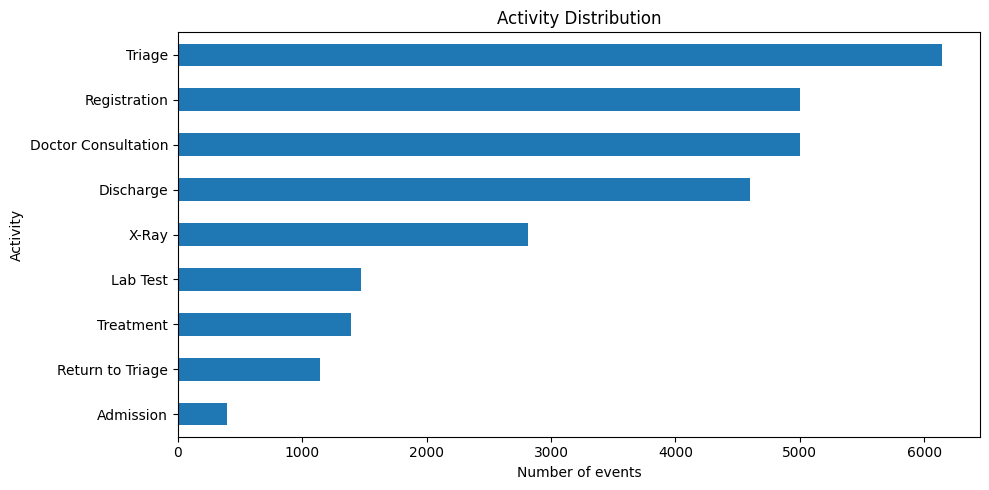

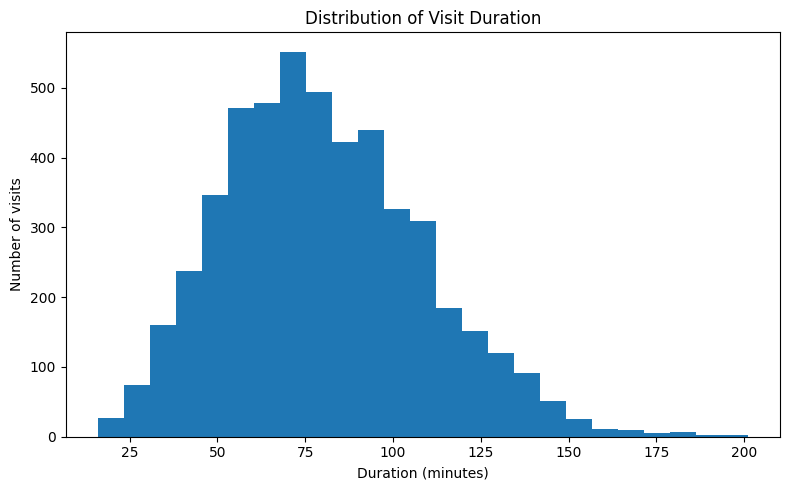

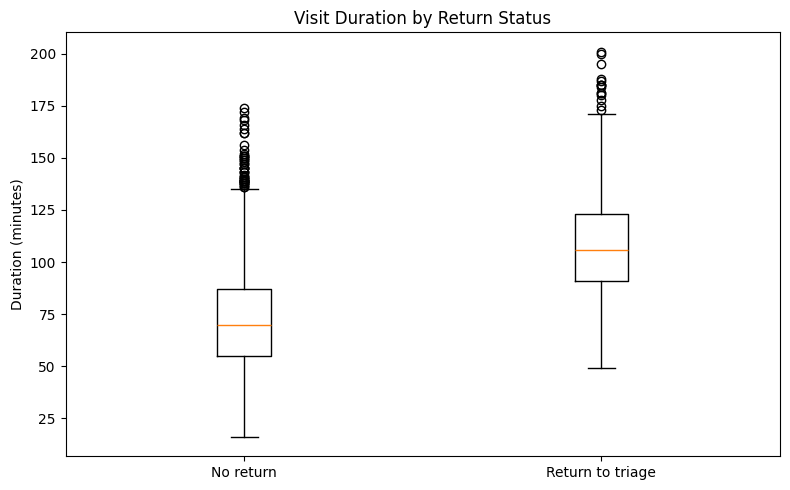

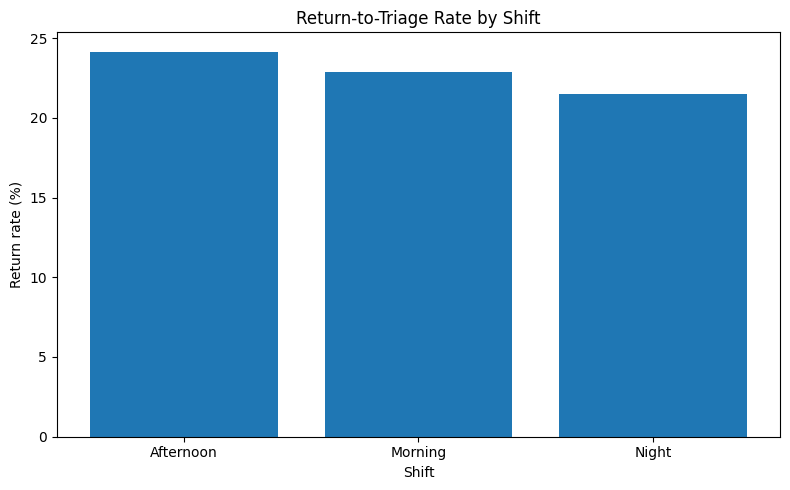

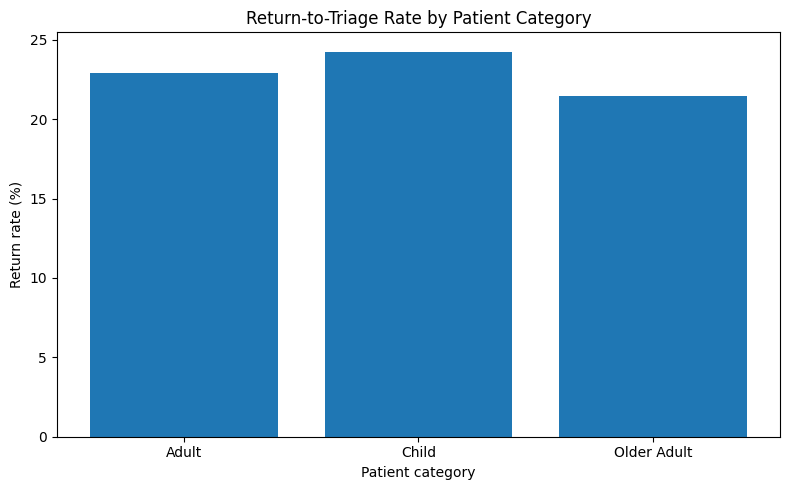


EDA completed successfully.


In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. DATA PREPARATION
# ==========================================
eda = df.copy()

eda["timestamp"] = pd.to_datetime(
    eda["timestamp"], errors="coerce", utc=True
)
eda = eda.dropna(
    subset=["case_id", "activity", "timestamp"]
)
eda = eda.sort_values(["case_id", "timestamp"]).copy()

# ==========================================
# 2. DATA QUALITY
# ==========================================
print("=" * 55)
print("CARE FLOW - EXPLORATORY DATA ANALYSIS")
print("=" * 55)

print("\nDataset shape:", eda.shape)
print("Unique visits:", eda["case_id"].nunique())
print("Unique activities:", eda["activity"].nunique())
print("Date range:", eda["timestamp"].min(), "to", eda["timestamp"].max())

print("\nMissing values:")
print(eda.isna().sum())

print("\nDuplicate event records:",
      eda.duplicated(
          subset=["case_id", "activity", "timestamp"]
      ).sum())

# ==========================================
# 3. VISIT-LEVEL SUMMARY
# ==========================================
visit_eda = (
    eda.groupby("case_id")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        event_count=("activity", "size"),
        shift=("shift", "first"),
        patient_category=("patient_category", "first")
    )
    .reset_index()
)

visit_eda["duration_minutes"] = (
    visit_eda["end_time"] - visit_eda["start_time"]
).dt.total_seconds() / 60

return_ids = set(
    eda.loc[
        eda["activity"].eq("Return to Triage"), "case_id"
    ].unique()
)

visit_eda["returned_to_triage"] = (
    visit_eda["case_id"].isin(return_ids)
)

print("\nVisit duration statistics (minutes):")
print(visit_eda["duration_minutes"].describe().round(2))

print("\nEvents per visit:")
print(visit_eda["event_count"].describe().round(2))

# ==========================================
# 4. ACTIVITY DISTRIBUTION
# ==========================================
activity_counts = eda["activity"].value_counts()

print("\nActivity counts:")
print(activity_counts)

# ==========================================
# 5. RETURN-TO-TRIAGE ANALYSIS
# ==========================================
total_visits = visit_eda["case_id"].nunique()
returned_visits = visit_eda["returned_to_triage"].sum()
return_rate = (
    returned_visits / total_visits * 100
    if total_visits else 0
)

print("\nTotal visits:", total_visits)
print("Visits with return to triage:", returned_visits)
print("Return-to-triage rate:", round(return_rate, 2), "%")

# Activity immediately before each event
eda["previous_activity"] = (
    eda.groupby("case_id")["activity"].shift(1)
)

print("\nActivity before Return to Triage:")
print(
    eda.loc[
        eda["activity"].eq("Return to Triage"),
        "previous_activity"
    ].value_counts()
)

# ==========================================
# 6. SHIFT-WISE ANALYSIS
# ==========================================
shift_eda = (
    visit_eda.groupby("shift", dropna=False)
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration=("duration_minutes", "mean")
    )
    .reset_index()
)

shift_eda["return_rate_pct"] = (
    shift_eda["return_visits"]
    / shift_eda["total_visits"] * 100
).round(2)

print("\nShift analysis:")
print(shift_eda.round(2).to_string(index=False))

# ==========================================
# 7. PATIENT-CATEGORY ANALYSIS
# ==========================================
category_eda = (
    visit_eda.groupby("patient_category", dropna=False)
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration=("duration_minutes", "mean")
    )
    .reset_index()
)

category_eda["return_rate_pct"] = (
    category_eda["return_visits"]
    / category_eda["total_visits"] * 100
).round(2)

print("\nPatient-category analysis:")
print(category_eda.round(2).to_string(index=False))

# ==========================================
# 8. VISUALIZATIONS
# ==========================================

# A. Activity frequency
plt.figure(figsize=(10, 5))
activity_counts.sort_values().plot(kind="barh")
plt.title("Activity Distribution")
plt.xlabel("Number of events")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

# B. Visit-duration distribution
plt.figure(figsize=(8, 5))
plt.hist(visit_eda["duration_minutes"], bins=25)
plt.title("Distribution of Visit Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of visits")
plt.tight_layout()
plt.show()

# C. Return vs no-return duration
duration_groups = [
    visit_eda.loc[
        ~visit_eda["returned_to_triage"], "duration_minutes"
    ],
    visit_eda.loc[
        visit_eda["returned_to_triage"], "duration_minutes"
    ]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    duration_groups,
    tick_labels=["No return", "Return to triage"]
)
plt.title("Visit Duration by Return Status")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

# D. Return rate by shift
plt.figure(figsize=(8, 5))
plt.bar(
    shift_eda["shift"].astype(str),
    shift_eda["return_rate_pct"]
)
plt.title("Return-to-Triage Rate by Shift")
plt.ylabel("Return rate (%)")
plt.xlabel("Shift")
plt.tight_layout()
plt.show()

# E. Return rate by patient category
plt.figure(figsize=(8, 5))
plt.bar(
    category_eda["patient_category"].astype(str),
    category_eda["return_rate_pct"]
)
plt.title("Return-to-Triage Rate by Patient Category")
plt.ylabel("Return rate (%)")
plt.xlabel("Patient category")
plt.tight_layout()
plt.show()

print("\nEDA completed successfully.")
